In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

from sklearn.manifold import TSNE

from common.configuration import species_invasive, species_native, species_classes_map, genetic_order_classes


In [2]:
trainval_cls_pred_path = "Save/trainval_classification_predictions.csv"
test_cls_pred_path = "Save/test_classification_predictions.csv"
hist_cls_pred_path = "Save/historical_classification_predictions.csv"

In [3]:
embeddings_colls = [str(i) for i in range(19)]

In [4]:
def sort_data_by_genetic_order(ref_x: np.ndarray, ref_y: pd.Series):
    sorted_pairs = sorted(
        zip(ref_x, ref_y), key=lambda x: genetic_order_classes.index(x[1]))

    # Unzip back to separate lists
    ref_x, ref_y = zip(*sorted_pairs)
    ref_x = np.array(ref_x)
    ref_y = pd.Series(ref_y)
    return ref_x, ref_y

In [5]:
test_cls_pred_pd = pd.read_csv(test_cls_pred_path, index_col=0)
test_cls_pred_pd = test_cls_pred_pd.sort_values(by="label", ignore_index=True)
test_cls_pred_masked_pd = test_cls_pred_pd.copy()
for m_label in species_invasive:
    test_cls_pred_masked_pd.loc[test_cls_pred_masked_pd.label == m_label, "label"] = "Unknown"

test_ref_x = test_cls_pred_masked_pd[embeddings_colls].to_numpy()
test_ref_y = test_cls_pred_masked_pd["label"]

test_ref_unmasked_x, test_ref_unmasked_y = sort_data_by_genetic_order(test_ref_x, test_cls_pred_pd["label"])


In [6]:
hist_cls_pred_pd = pd.read_csv(hist_cls_pred_path, index_col=0)
# hist_cls_pred_masked_pd = hist_cls_pred_pd.copy()

hist_cls_pred_pd.loc[hist_cls_pred_pd.label == "Populus", "label"] = "Populus tremula"
hist_cls_pred_pd.loc[hist_cls_pred_pd.label == "Gramineae", "label"] = "Poaceae"
hist_cls_pred_pd.loc[hist_cls_pred_pd.label == "0_Not pollen", "label"] = "Not pollen"
hist_cls_pred_pd.loc[hist_cls_pred_pd.label == "0_Unknown-pollen", "label"] = "Unknown"


hist_cls_pred_pd = hist_cls_pred_pd.sort_values(by="label", ignore_index=True)

hist_x = hist_cls_pred_pd[embeddings_colls].to_numpy()
hist_x, hist_y = sort_data_by_genetic_order(hist_x, hist_cls_pred_pd["label"])

In [7]:
def get_cmap(n, name='hsv'):
    '''Returns a function that maps each index in 0, 1, ..., n-1 to a distinct 
    RGB color; the keyword argument name must be a standard mpl colormap name.'''
    return plt.cm.get_cmap(name, n)

def plot_tsne(embeddings_data, labels_data_str, subtitle: str = None, file_name=None):
    class_to_indices = {c: [] for c in genetic_order_classes}
    for i, label in enumerate(labels_data_str):
        class_to_indices[label].append(i)
    vectors = np.array(embeddings_data)
    colors = get_cmap(len(class_to_indices.items()))
    
    labels = [""] * vectors.shape[0]

    for class_name, indices in class_to_indices.items():
        for index in indices:
            labels[index] = class_name
    
    tsne = TSNE(n_components=2, random_state=42, perplexity=20, metric="euclidean", n_jobs=-1, early_exaggeration=12)#cosine
    vectors_2d = tsne.fit_transform(vectors)
    
    plt.figure(figsize=(8, 6))
    for i, (class_name, indices) in enumerate(class_to_indices.items()):
        mask = np.isin(range(vectors.shape[0]), indices)
        plt.scatter(vectors_2d[mask, 0], vectors_2d[mask, 1], s=1.0,
                    label=class_name, color=colors(i), alpha=0.6)
    
    plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    if subtitle: 
        plt.title("t-SNE visualization of image features\n"+subtitle)
    else:
        plt.title("t-SNE visualization of image features")
    plt.tight_layout()
    if file_name:
        plt.savefig(file_name)
    plt.show()

C:\Users\Александр\AppData\Local\Temp\ipykernel_13732\3266527570.py:4: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  return plt.cm.get_cmap(name, n)


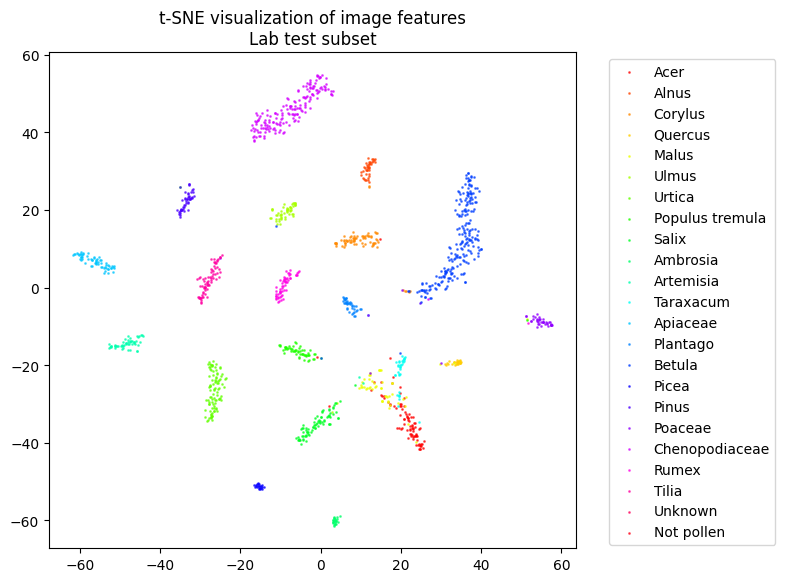

In [8]:
plot_tsne(np.concatenate([test_ref_unmasked_x]), np.concatenate([test_ref_unmasked_y]), subtitle="Lab test subset", file_name=os.path.join("out", "tsne_lab_test.svg"))

C:\Users\Александр\AppData\Local\Temp\ipykernel_13732\3266527570.py:4: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  return plt.cm.get_cmap(name, n)


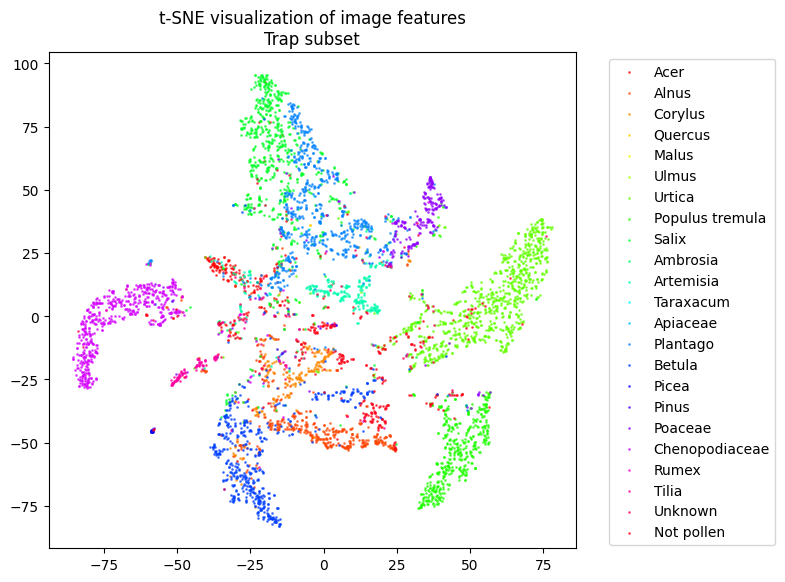

In [9]:
plot_tsne(np.concatenate([hist_x]), np.concatenate([hist_y]), subtitle="Trap subset", file_name=os.path.join("out", "tsne_trap_test.svg"))

C:\Users\Александр\AppData\Local\Temp\ipykernel_13732\3266527570.py:4: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  return plt.cm.get_cmap(name, n)


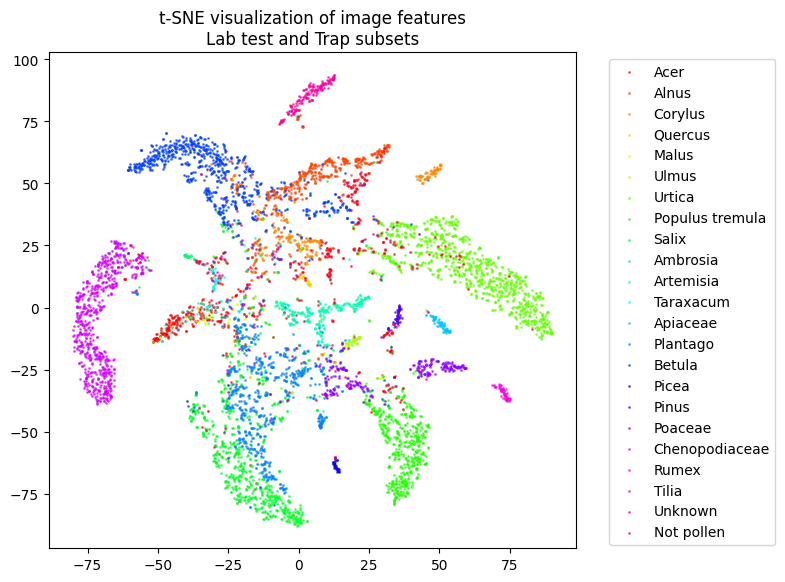

In [10]:
plot_tsne(np.concatenate([test_ref_unmasked_x, hist_x]), np.concatenate([test_ref_unmasked_y, hist_y]), subtitle="Lab test and Trap subsets", file_name=os.path.join("out", "tsne_lab_trap.svg"))